[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/sampriti-sr/MLP_Course/blob/kshitij-variant/docs/lifecycle/05-splitting.ipynb)

# Splitting Strategy

<div class="admonition info">
<p class="admonition-title">What you will be able to do after this page</p>
<ul>
<li>Explain the two ways a (customer, date) table leaks between train and test.</li>
<li>Measure how much a flawed split flatters a model, and why weak models hide it.</li>
<li>Choose a split that matches how the model will be used, with an embargo of one horizon.</li>
<li>State and follow the test-set protocol.</li>
</ul>
</div>

**Prerequisites:** <a href="../04-eda/">Exploratory Analysis</a>. **Dataset:** Online Retail II. **Time:** about 40 minutes.

In [1]:
try:
    import mlp_data
except ImportError:  # e.g. a fresh Colab runtime
    %pip install -q "mlp-course @ git+https://github.com/sampriti-sr/MLP_Course@kshitij-variant"
    import mlp_data

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from mlp_data import load_retail, retail, style

style.apply()
pd.set_option("display.width", 120)
pd.set_option("display.max_columns", 14)
pd.set_option("display.float_format", "{:,.2f}".format)

## The situation

Every model we build from here on will be judged by a number. Whether that number means anything depends almost entirely on **how we split the data** into the part the model learns from and the part we judge it on. A bad split does not crash. It quietly produces a score that looks good and then fails in production.

The goal of a split is simple to state: **make the evaluation look like the real future**. In deployment, we will stand on a date, look at customers we have already seen, and predict what they do next. Our split must recreate exactly that.

## Two ways a split leaks

Our table has one row per *(customer, snapshot date)*. That structure creates two separate leaks.

**Leak 1: the same customer on both sides.** A customer appears in every monthly snapshot, with nearly the same features and often the same label. If rows are shuffled, a customer's August row can train the model while their September row tests it: the model is "tested" on something it has effectively already seen.

**Leak 2: overlapping time.** The label looks 90 days ahead. A training row whose label window runs *into* the test period lets the model learn about events from the very period we claim to predict.

Let us measure both, using a **sandbox** of earlier snapshots (March to September 2010) so we do not touch the periods reserved for validation and testing.

In [2]:
cleaned = retail.clean_retail(load_retail())
sales, returns = cleaned.sales, cleaned.returns

sandbox = pd.date_range("2010-03-01", "2010-09-01", freq="MS")             # seven monthly snapshots
pool = retail.make_snapshots(sales, returns, sandbox, features="full")
print(f"{len(pool):,} rows from {pool['customer_id'].nunique():,} distinct customers: about {len(pool) / pool['customer_id'].nunique():.1f} rows per customer")

18,328 rows from 3,299 distinct customers: about 5.6 rows per customer


In [3]:
from sklearn.model_selection import train_test_split

tr, te = train_test_split(pool, test_size=0.25, random_state=0)             # the usual shuffled split
print(f"Leak 1: {te['customer_id'].isin(tr['customer_id']).mean():.0%} of the test rows belong to a customer who is also in the training set")

# How similar is the same customer from one month to the next?
a = pool[pool["cutoff"] == "2010-08-01"].set_index("customer_id")
b = pool[pool["cutoff"] == "2010-09-01"].set_index("customer_id")
both = a.index.intersection(b.index)
print(f"customers present in both August and September: {len(both):,}")
print(f"  same label in both months: {(a.loc[both, 'y'] == b.loc[both, 'y']).mean():.0%}")
print(f"  rank correlation of past-year spend: {a.loc[both, 'monetary'].corr(b.loc[both, 'monetary'], method='spearman'):.2f}")

h = 90
overlap = pd.DataFrame({"gap before test snapshot (days)": [30, 60, 90]})
overlap["label days shared with the test period"] = (h - overlap["gap before test snapshot (days)"]).clip(lower=0)
print("\nLeak 2: how much of a training label window falls inside the test period"); overlap.set_index("gap before test snapshot (days)")

Leak 1: 98% of the test rows belong to a customer who is also in the training set
customers present in both August and September: 3,136
  same label in both months: 86%
  rank correlation of past-year spend: 0.98

Leak 2: how much of a training label window falls inside the test period


,label days shared with the test period
gap before test snapshot (days),
30,60
60,30
90,0


**Leak 1** is near-total under a shuffled split, and consecutive snapshots of one customer are close to duplicates. **Leak 2** is smaller but real: a training snapshot only 30 days before the test snapshot shares two thirds of its label window with the test period. The fix for Leak 2 is an **embargo**: keep training snapshots at least one full horizon (90 days) before the test snapshot, so no training label window overlaps it.

## Does it matter? Measure it

Four ways to split the same pool. For each, we record what the split *estimated* the model's quality to be (AUC on its own test part), and the model's **real** quality on the genuine future: the December 2010 snapshot, which none of the schemes ever saw.

- **A. Random rows**: shuffle rows, hold out 25%.
- **B. Hold out whole customers**: no customer on both sides.
- **C. Time split, no gap**: train on every earlier snapshot, test on the last (September).
- **D. Time split with embargo**: as C, but only snapshots whose 90-day label window ends before September begins.

We run this twice, with a **simple** setup (a gradient-boosted model on recency, frequency and spend) and a **flexible** setup (a deep random forest on the full feature set). A flexible model can memorise; a simple one cannot.

In [4]:
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import GroupShuffleSplit

future = retail.make_snapshot(sales, returns, "2010-12-01", features="full").reset_index()   # the real "next period"
last = sandbox[-1]

def compare_schemes(feature_cols, make_model):
    fit = lambda d: make_model().fit(d[feature_cols].fillna(-1), d["y"])
    auc = lambda m, d: roc_auc_score(d["y"], m.predict_proba(d[feature_cols].fillna(-1))[:, 1])
    out = {}
    tr, te = train_test_split(pool, test_size=0.25, random_state=0)
    m = fit(tr); out["A. random rows"] = (auc(m, te), auc(m, future))
    i, j = next(GroupShuffleSplit(1, test_size=0.25, random_state=0).split(pool, groups=pool["customer_id"]))
    m = fit(pool.iloc[i]); out["B. hold out customers"] = (auc(m, pool.iloc[j]), auc(m, future))
    test_snap = pool[pool["cutoff"] == last]
    m = fit(pool[pool["cutoff"] < last]); out["C. time split, no gap"] = (auc(m, test_snap), auc(m, future))
    m = fit(pool[pool["cutoff"] + pd.Timedelta(days=h) <= last]); out["D. time split + embargo"] = (auc(m, test_snap), auc(m, future))
    t = pd.DataFrame(out, index=["estimated", "real"]).T
    t["optimism"] = t["estimated"] - t["real"]
    return t

rfm = ["recency_days", "frequency", "monetary"]
everything = [c for c in pool.columns if c not in ("customer_id", "cutoff", "y")]
simple = compare_schemes(rfm, lambda: HistGradientBoostingClassifier(max_iter=100, random_state=0))
flexible = compare_schemes(everything, lambda: RandomForestClassifier(n_estimators=300, min_samples_leaf=1, n_jobs=-1, random_state=0))

fmt = "{:+.3f}".format
print("SIMPLE: gradient boosting on recency, frequency, spend"); print(simple.to_string(float_format="{:.3f}".format))
print("\nFLEXIBLE: deep random forest on all features"); print(flexible.to_string(float_format="{:.3f}".format))

SIMPLE: gradient boosting on recency, frequency, spend
                         estimated  real  optimism
A. random rows               0.747 0.768    -0.021
B. hold out customers        0.741 0.773    -0.032
C. time split, no gap        0.732 0.772    -0.040
D. time split + embargo      0.710 0.758    -0.048

FLEXIBLE: deep random forest on all features
                         estimated  real  optimism
A. random rows               0.829 0.756     0.073
B. hold out customers        0.717 0.747    -0.031
C. time split, no gap        0.808 0.750     0.058
D. time split + embargo      0.696 0.742    -0.046


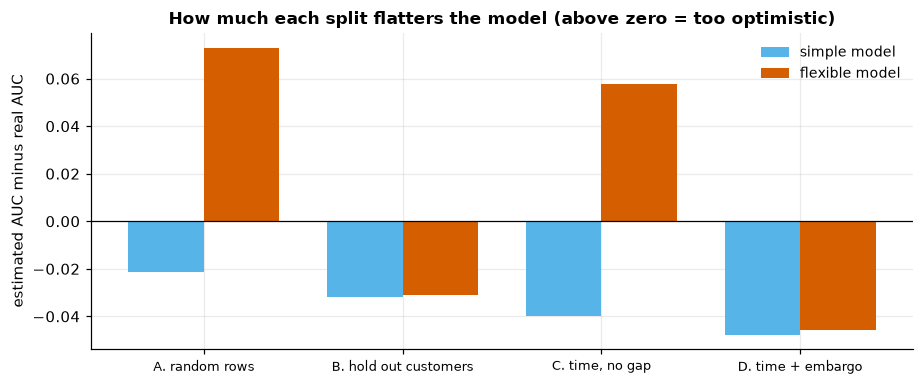

In [5]:
fig, ax = plt.subplots(figsize=(8.5, 3.6))
w, xs = 0.38, np.arange(4)
ax.bar(xs - w / 2, simple["optimism"], w, label="simple model", color=style.SKY)
ax.bar(xs + w / 2, flexible["optimism"], w, label="flexible model", color=style.RED)
ax.axhline(0, color="black", lw=0.8)
ax.set_xticks(xs, [s.split(". ")[0] + ". " + s.split(". ")[1].replace("time split", "time") for s in simple.index], fontsize=8.5)
ax.set(ylabel="estimated AUC minus real AUC", title="How much each split flatters the model (above zero = too optimistic)"); ax.legend()
plt.tight_layout(); plt.show()

# The claims made in the text below are checked, not just asserted in prose.
assert flexible.loc["A. random rows", "optimism"] > 0.03 and flexible.loc["C. time split, no gap", "optimism"] > 0.03
assert flexible.loc["D. time split + embargo", "optimism"] < 0 and flexible.loc["B. hold out customers", "optimism"] < 0
assert simple["estimated"].max() - simple["estimated"].min() < 0.05

**Reading the chart.** With the **simple** model (light bars) the choice of split barely changes the estimate: all four are within a few hundredths of each other. If that were your only experiment you would conclude "the split doesn't matter".

With the **flexible** model (red bars) the picture changes sharply. A random split and a naive time split report a score about **0.06 to 0.07 too high**: the forest is rewarded for recognising customers it has half-seen, and for peeking at the overlap. The two splits that block those leaks, B and D, are *not* optimistic. They are slightly **conservative**: they use less training data and test a harder, more honest question.

<div class="admonition warning">
<p class="admonition-title">The danger grows as the model improves</p>
<p>A leaky split is nearly harmless for weak models and increasingly rewarding for strong ones. So the better you get at modelling, the more a flawed split will flatter you, and you will not notice, because the number keeps going up. Fix the split <strong>before</strong> you start tuning, not after.</p>
</div>

## Which honest split is right for us?

Both B and D were honest, but they answer different questions.

- **B (hold out whole customers)** asks: *how well do we predict for customers we have never seen?* That is the right test for a model deployed on **new** customers.
- **D (time split with embargo)** asks: *standing on a date, how well do we predict the near future for the customers we already know?* That is exactly our deployment: every month we score customers who have already bought from us.

So **we use a chronological split with an embargo**. Notice that it is fine, and expected, for the same customers to appear in training and in validation, because in production the customers are the same people a month later. What is *not* allowed is training on any information from the validation or test period.

## Our actual split

Three roles, each with a job:

| Set | Job | Allowed to look at it |
|---|---|---|
| **Train** | the model learns from it | freely |
| **Validation** | choose between models, tune settings, decide when to stop | repeatedly |
| **Test** | the final, honest verdict | **once** |

In [6]:
sp = retail.build_splits(sales, returns, features="full")        # raises if any label window overlaps the next period
print("train cutoffs:", [c.date().isoformat() for c in retail.TRAIN_CUTOFFS])
print("validation cutoff:", retail.VALID_CUTOFF.date(), "| test cutoff:", retail.TEST_CUTOFF.date())

day = pd.Timedelta(days=retail.HORIZON_DAYS)
assert max(retail.TRAIN_CUTOFFS) + day <= retail.VALID_CUTOFF          # train labels end before validation starts
assert retail.VALID_CUTOFF + day <= retail.TEST_CUTOFF                 # validation labels end before test starts
assert retail.TEST_CUTOFF + day <= sales["invoice_date"].max()         # the last window is not past the data
print(f"last training label window ends {(max(retail.TRAIN_CUTOFFS) + day).date()}; validation snapshot is {retail.VALID_CUTOFF.date()}")
print(f"validation label window ends {(retail.VALID_CUTOFF + day).date()}; test snapshot is {retail.TEST_CUTOFF.date()}")
print(f"test label window ends {(retail.TEST_CUTOFF + day).date()}; data ends {sales['invoice_date'].max().date()}")

train cutoffs: ['2010-12-01', '2011-01-01', '2011-02-01', '2011-03-01']
validation cutoff: 2011-06-01 | test cutoff: 2011-09-01
last training label window ends 2011-05-30; validation snapshot is 2011-06-01
validation label window ends 2011-08-30; test snapshot is 2011-09-01
test label window ends 2011-11-30; data ends 2011-12-09


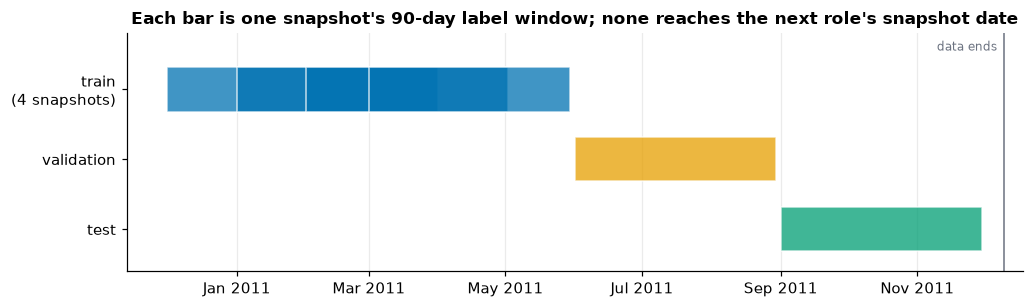

In [7]:
import matplotlib.dates as mdates

colors = {"train": style.BLUE, "validation": style.ORANGE, "test": style.GREEN}
snapshots = [("train", c) for c in retail.TRAIN_CUTOFFS] + [("validation", retail.VALID_CUTOFF), ("test", retail.TEST_CUTOFF)]
row = {"train": 2, "validation": 1, "test": 0}

fig, ax = plt.subplots(figsize=(9.5, 2.9))
for role, cutoff in snapshots:                                   # one bar per snapshot: its 90-day label window
    ax.broken_barh([(mdates.date2num(cutoff), retail.HORIZON_DAYS)], (row[role] - 0.32, 0.64), facecolors=colors[role], alpha=0.75, edgecolor="white")
data_end = mdates.date2num(sales["invoice_date"].max())
ax.axvline(data_end, color=style.GREY, lw=1)
ax.text(data_end - 3, 2.55, "data ends", ha="right", fontsize=8, color=style.GREY)
ax.set_yticks([2, 1, 0], ["train\n(4 snapshots)", "validation", "test"]); ax.set_ylim(-0.6, 2.8)
ax.xaxis_date(); ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y")); ax.grid(axis="y", visible=False)
ax.set_title("Each bar is one snapshot's 90-day label window; none reaches the next role's snapshot date")
plt.tight_layout(); plt.show()

In [8]:
summary = pd.DataFrame({
    "snapshots": [len(retail.TRAIN_CUTOFFS), 1, 1],
    "customer-snapshots": [len(sp.train), len(sp.valid), len(sp.test)],
    "distinct customers": [sp.train["customer_id"].nunique(), sp.valid["customer_id"].nunique(), sp.test["customer_id"].nunique()],
    "buys again": [f"{sp.train['y'].mean():.1%}", f"{sp.valid['y'].mean():.1%}", "not looked at"],
}, index=["train", "validation", "test"])
summary

,snapshots,customer-snapshots,distinct customers,buys again
train,4,16925,4512,34.4%
validation,1,4324,4324,36.6%
test,1,4324,4324,not looked at


We print the repurchase rate for train and validation, which we are allowed to study, and deliberately **not** for test. Looking at the test labels now would tempt us to adjust our plans to them.

<div class="admonition tip">
<p class="admonition-title">The test-set protocol</p>
<ol>
<li>Build the test set now and <strong>put it away</strong>. Do not explore it, plot it, or "just check".</li>
<li>Make every decision (features, model, settings) using train and validation only.</li>
<li>Run the test set <strong>once</strong>, at the very end, and report that number whatever it is.</li>
<li>If you run it, dislike the result, and change the model, the test set has become a second validation set. You then have no honest estimate left. (In real life, collect new data.)</li>
</ol>
</div>

## A note on seasons

Validation (June) and test (September) sit in different seasons. That is deliberate and realistic: a model validated in the quiet months is judged on a window that reaches into the autumn peak, just as it would be in production. A chronological split therefore gives an honest picture of *change* as well as of skill. We do not look at the test labels to see how much they change; the drift page studies that question properly, after the test verdict is in.

## Check yourself

<details class="question">
<summary>1. With the simple model the split made almost no difference. Why is that not a reason to use a random split?</summary>

Because the leak is still there; the simple model just cannot exploit it. As soon as you improve the model (richer features, more capacity) a random split starts rewarding memorisation, and the estimate climbs for the wrong reason. A split should be correct by design, not correct by luck of your current model being weak.

</details>

<details class="question">
<summary>2. Hold-out-customers (B) gave a lower estimate than reality. If it is honest, why is it pessimistic here?</summary>

It answers a harder question than ours: predicting for customers the model has *never seen*, with less training data, whereas in production we score customers we already know. Different honest splits answer different questions; choose the one that matches how the model will be used.

</details>

<details class="question">
<summary>3. Why must the embargo be a full 90 days, not 30?</summary>

Because the label looks 90 days ahead. A training snapshot 30 days before the validation snapshot has a label window that overlaps the validation period by 60 days, so the training labels *contain* validation-period events. Only a gap of one full horizon guarantees no training label touches the period we later judge on.

</details>

## Exercise

<details class="question">
<summary>What share of the validation customers also appear in the training snapshots? Predict it, then compute it, and explain why it is acceptable.</summary>

```python
seen = sp.valid["customer_id"].isin(sp.train["customer_id"]).mean()
print(f"{seen:.0%} of validation customers also appear in training")
```

Most do, and that is **correct**: in production we score the same customers month after month. What would be wrong is any training *information from the validation period* (the embargo prevents that), not the presence of the same customers. If the share were 0% we would be testing a different question, such as new-customer prediction.

</details>

## Recap

- The goal of a split is to **look like the real future**. Decide what "the future" is before you choose how to split.
- Rows from the same entity and from overlapping time are not independent; shuffling them leaks.
- The harm is **invisible with weak models and grows with strong ones**, so fix the split before you tune.
- Chronological split with a one-horizon **embargo** matches our deployment (known customers, next 90 days). Hold-out-by-customer answers a different question.
- Train learns, validation chooses, **test speaks once**.

**Next:** *Baselines*, where we measure what a trivial rule and a plain model achieve on the validation set, so every later model has a bar to clear.